**NOMBRE: JUAN DAMIAN CAMARENA ARELLANO**

**MATRICULA: 2177944**

# Parte práctica - Dataset Auto MPG
## Parte 1: Carga y Limpieza de Datos

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [36]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)

In [37]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [38]:
df.dtypes

,0
mpg,float64
cylinders,int64
displacement,float64
horsepower,float64
weight,int64
acceleration,float64
model_year,int64
origin,object
name,object


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [40]:
df["horsepower"].isnull().sum()

np.int64(6)

In [41]:
mediana_hp = df["horsepower"].median()
df["horsepower"] = df["horsepower"].fillna(mediana_hp)

In [42]:
df["horsepower"].isnull().sum()

np.int64(0)

In [43]:
df["relacion_peso_potencia"] = df["weight"] / df["horsepower"]

In [44]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,relacion_peso_potencia
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu,26.953846
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320,22.381818
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite,22.906667
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst,22.886667
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino,24.635714


## Parte 2: Visualización de Datos

Histograma:

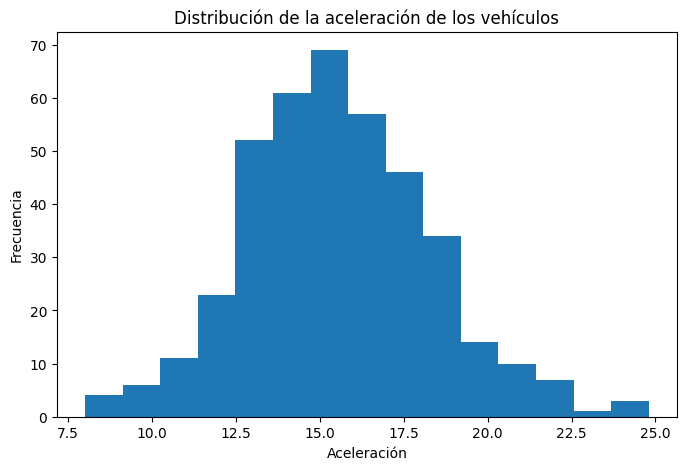

In [45]:
plt.figure(figsize=(8,5))
plt.hist(df["acceleration"], bins=15)
plt.title("Distribución de la aceleración de los vehículos")
plt.xlabel("Aceleración")
plt.ylabel("Frecuencia")
plt.show()

Gráfico de Dispersión (Scatter):

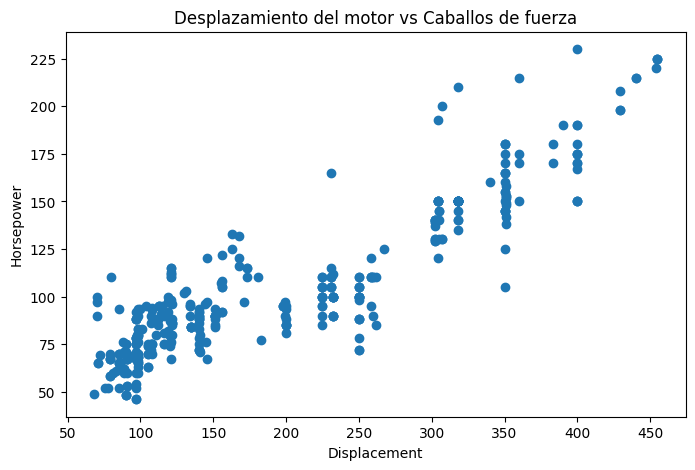

In [46]:
plt.figure(figsize=(8,5))
plt.scatter(df["displacement"], df["horsepower"])
plt.title("Desplazamiento del motor vs Caballos de fuerza")
plt.xlabel("Displacement")
plt.ylabel("Horsepower")
plt.show()

In [47]:
promedio_mpg = df.groupby("origin")["mpg"].mean()
promedio_mpg

,mpg
origin,
europe,27.891429
japan,30.450633
usa,20.083534


Gráfico de Barras:

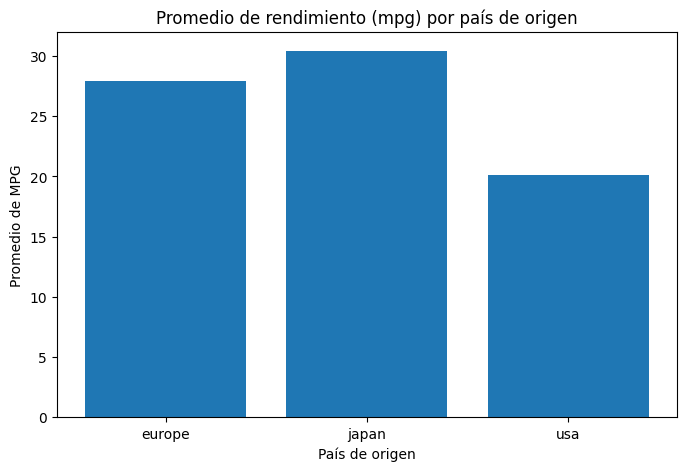

In [48]:
plt.figure(figsize=(8,5))
plt.bar(promedio_mpg.index, promedio_mpg.values)
plt.title("Promedio de rendimiento (mpg) por país de origen")
plt.xlabel("País de origen")
plt.ylabel("Promedio de MPG")
plt.show()